In [18]:
# ============================================================
# IMPORTS AND CONFIGURATION
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_DIR = "../data"
OUTPUT_DIR = "../outputs/unsupervised"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "plots"), exist_ok=True)

print("Output directory:", os.path.abspath(OUTPUT_DIR))

Output directory: c:\Users\devra\Music\gas-turbine-ml\outputs\unsupervised


In [19]:
# ============================================================
# LOAD DATASETS
# ============================================================

years = [2011, 2012, 2013, 2014, 2015]
frames = []

for year in years:
    path = os.path.join(DATA_DIR, f"gt_{year}.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Cannot find {path}. Update DATA_DIR in Section 1.")
    df_year = pd.read_csv(path)
    df_year["YEAR"] = year
    frames.append(df_year)

data = pd.concat(frames, ignore_index=True)

print("Dataset shape:", data.shape)
display(data.head())
display(data.groupby("YEAR").size().rename("observations").to_frame())

Dataset shape: (36733, 12)


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,YEAR
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


,observations
YEAR,
2011,7411
2012,7628
2013,7152
2014,7158
2015,7384


In [20]:
# ============================================================
# FEATURES AND TARGETS
# ============================================================

feature_cols = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]
target_cols = ["TEY", "CO", "NOX"]

required = feature_cols + target_cols + ["YEAR"]
missing = [col for col in required if col not in data.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

X_all = data[feature_cols].copy()
if X_all.isna().any().any() or np.isinf(X_all.to_numpy()).any():
    raise ValueError("Clustering features contain missing or infinite values.")

print("Clustering inputs:", feature_cols)
print("Interpretation targets:", target_cols)

Clustering inputs: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'CDP']
Interpretation targets: ['TEY', 'CO', 'NOX']


In [21]:
# ============================================================
# DEVELOPMENT AND COMPARISON DATA
# ============================================================

development_data = data[data["YEAR"] <= 2014].copy().reset_index(drop=True)
comparison_data = data[data["YEAR"] == 2015].copy().reset_index(drop=True)

X_dev = development_data[feature_cols]
X_2015 = comparison_data[feature_cols]

print("2011–2014 development rows:", len(X_dev))
print("2015 comparison rows:", len(X_2015))

2011–2014 development rows: 29349
2015 comparison rows: 7384


In [22]:
# ============================================================
# FEATURE SCALING
# ============================================================

scaler = StandardScaler()
X_dev_scaled = scaler.fit_transform(X_dev)
X_2015_scaled = scaler.transform(X_2015)

print("Scaled matrices:", X_dev_scaled.shape, X_2015_scaled.shape)

Scaled matrices: (29349, 8) (7384, 8)


In [23]:
# ============================================================
# K-MEANS MODEL SELECTION
# ============================================================

kmeans_rows = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_dev_scaled)
    sizes = pd.Series(labels).value_counts()

    score = silhouette_score(
        X_dev_scaled, labels,
        sample_size=min(5000, len(X_dev_scaled)),
        random_state=RANDOM_STATE
    )

    kmeans_rows.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": score,
        "Minimum Cluster Size": int(sizes.min()),
        "Maximum Cluster Size": int(sizes.max())
    })

kmeans_search = pd.DataFrame(kmeans_rows)
display(kmeans_search)
kmeans_search.to_csv(os.path.join(OUTPUT_DIR, "kmeans_silhouette_results.csv"), index=False)

,K,Inertia,Silhouette Score,Minimum Cluster Size,Maximum Cluster Size
0,2,153370.899507,0.369982,7079,22270
1,3,116253.784796,0.287206,5335,13761
2,4,94192.426884,0.291010,5147,10024
3,5,83982.855237,0.267770,5007,7008
4,6,75671.123038,0.263723,2983,6446
5,7,70219.345517,0.258171,2097,6183
6,8,66379.382378,0.247904,2074,6121
7,9,62702.958234,0.249626,1411,6039
8,10,59249.234475,0.240274,1358,4635


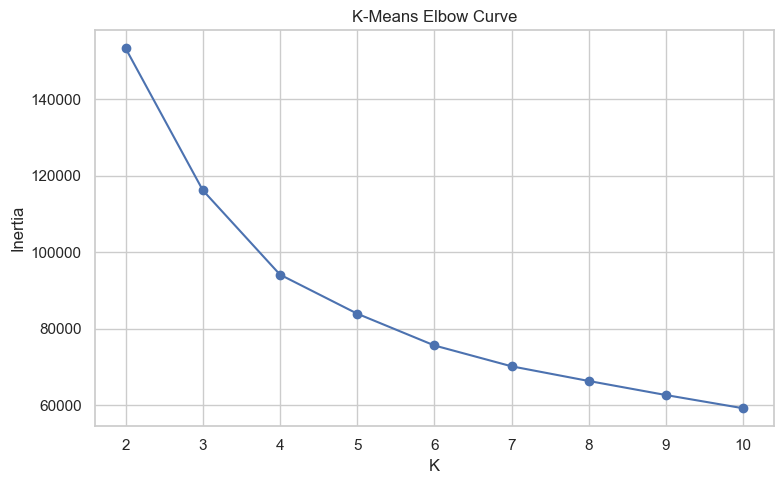

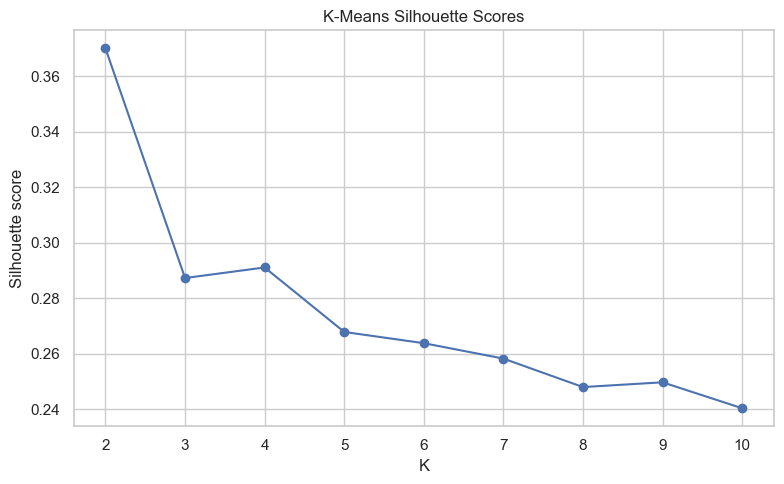

In [24]:
# ============================================================
# K-MEANS EVALUATION PLOTS
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(kmeans_search["K"], kmeans_search["Inertia"], marker="o")
ax.set(xlabel="K", ylabel="Inertia", title="K-Means Elbow Curve")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "kmeans_elbow_curve.png"), dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(kmeans_search["K"], kmeans_search["Silhouette Score"], marker="o")
ax.set(xlabel="K", ylabel="Silhouette score", title="K-Means Silhouette Scores")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "kmeans_silhouette_curve.png"), dpi=300)
plt.show()

In [25]:
# ============================================================
# FINAL K-MEANS MODEL
# ============================================================

# Review Sections 6–7 before finalizing this candidate value.
SELECTED_K = 4

kmeans_model = KMeans(
    n_clusters=SELECTED_K,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels_dev = kmeans_model.fit_predict(X_dev_scaled)
kmeans_labels_2015 = kmeans_model.predict(X_2015_scaled)

development_data["KMeans_Cluster"] = kmeans_labels_dev
comparison_data["KMeans_Cluster"] = kmeans_labels_2015

display(development_data["KMeans_Cluster"].value_counts().sort_index().to_frame("count"))
display(comparison_data["KMeans_Cluster"].value_counts().sort_index().to_frame("count"))

,count
KMeans_Cluster,
0,10024
1,5147
2,7571
3,6607


,count
KMeans_Cluster,
0,2158
1,936
2,2554
3,1736


AT                                                     AP  \
                count       mean   median       std       min     max  count   
KMeans_Cluster                                                                 
0               10024  14.430715  14.2935  5.494200   0.38289  28.863  10024   
1                5147  13.496414  12.8870  5.597173   0.28985  31.577   5147   
2                7571  26.124677  26.3750  3.663614  10.00500  34.929   7571   
3                6607  16.882216  17.4340  6.108993   0.50370  32.391   6607   

                                               ...     TAT                    \
                       mean  median       std  ...  median       std     min   
KMeans_Cluster                                 ...                             
0               1013.800588  1013.6  6.419261  ...  549.98  1.225238  530.57   
1               1015.218982  1015.3  6.799565  ...  532.36  5.275747  513.06   
2               1009.977291  1010.3  4.371818  ...  549.91  3.497512  532.41   
3               1012.223981  1012.1  6.348637  ...  549.94  4.079458  511.04   

                          CDP                                                
                   max  count       mean  median       std      min     max  
KMeans_Cluster                                                               
0               550.56  10024  11.887654  11.898  0.249439  10.9420  13.214  
1               546.52   5147  13.788877  13.801  0.341263  11.6810  15.081  
2               550.61   7571  12.340868  12.201  0.532318  10.3820  13.680  
3               550.52   6607  10.614338  10.550  0.286252   9.8518  11.594  

[4 rows x 48 columns]

TEY                                                   CO  \
                count        mean  median       std     min     max  count   
KMeans_Cluster                                                               
0               10024  132.991458  133.74  4.045966  116.96  154.29  10024   
1                5147  157.896305  157.95  5.420411  120.55  174.61   5147   
2                7571  135.813422  133.85  7.548373  105.26  155.80   7571   
3                6607  112.099520  110.78  4.718493  100.03  129.08   6607   

                                                                NOX  \
                    mean  median       std       min     max  count   
KMeans_Cluster                                                        
0               1.662399  1.5283  1.116359  0.001640  34.467  10024   
1               1.053842  0.9740  0.952266  0.000388  34.496   5147   
2               1.428863  1.3587  0.995177  0.001594  32.676   7571   
3               4.711688  4.1511  3.146147  0.006915  44.103   6607   

                                                              
                     mean  median        std     min     max  
KMeans_Cluster                                                
0               68.727899  67.175  10.153357  38.254  119.39  
1               66.688892  66.666   7.582073  29.063  106.63  
2               62.305567  62.598   7.762720  27.183  119.91  
3               68.455742  64.119  16.652678  38.011  119.90

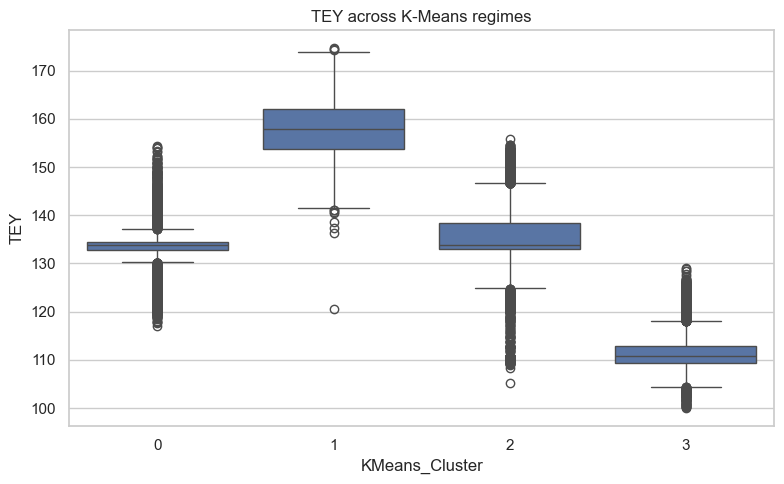

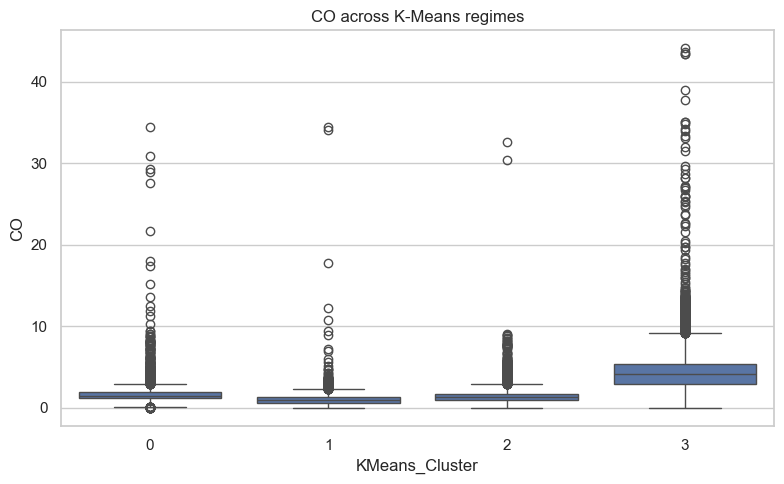

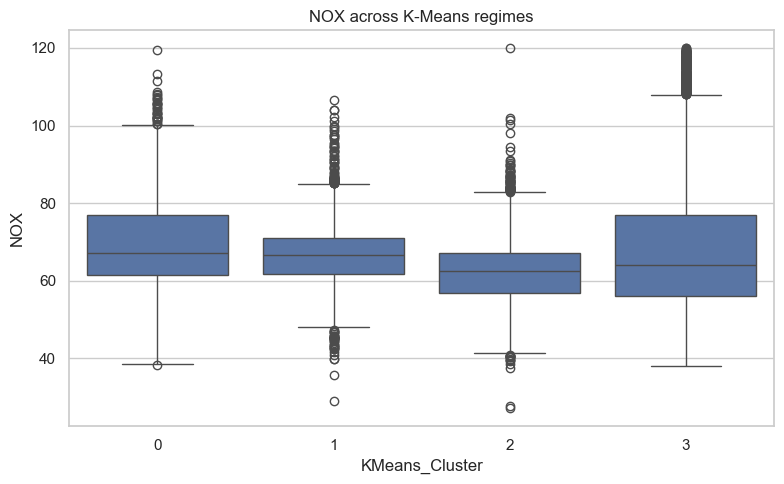

In [26]:
# ============================================================
# K-MEANS CLUSTER PROFILES
# ============================================================

kmeans_feature_profiles = development_data.groupby("KMeans_Cluster")[feature_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
kmeans_target_profiles = development_data.groupby("KMeans_Cluster")[target_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(kmeans_feature_profiles)
display(kmeans_target_profiles)

kmeans_feature_profiles.to_csv(os.path.join(OUTPUT_DIR, "kmeans_feature_profiles.csv"))
kmeans_target_profiles.to_csv(os.path.join(OUTPUT_DIR, "kmeans_cluster_profiles.csv"))

for target in target_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=development_data, x="KMeans_Cluster", y=target)
    plt.title(f"{target} across K-Means regimes")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"kmeans_{target}_distribution.png"), dpi=300)
    plt.show()

PCA explained variance ratio: [0.4953579  0.22596894]
Total variance explained: 0.7213268390569108


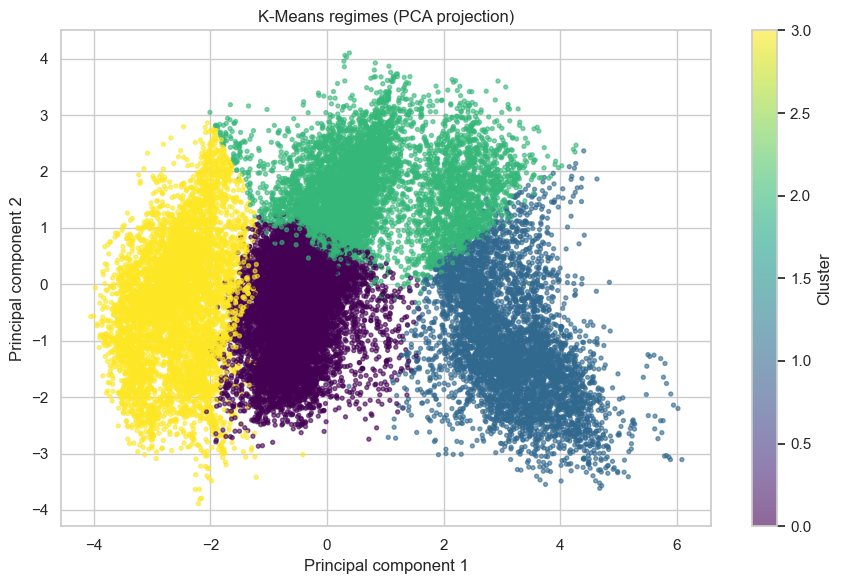

In [27]:
# ============================================================
# PCA K-MEANS VISUALIZATION
# ============================================================

pca = PCA(n_components=2)
X_dev_pca = pca.fit_transform(X_dev_scaled)
X_2015_pca = pca.transform(X_2015_scaled)

print("PCA explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))
sc = plt.scatter(
    X_dev_pca[:, 0], X_dev_pca[:, 1],
    c=kmeans_labels_dev, cmap="viridis", s=8, alpha=0.6
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("K-Means regimes (PCA projection)")
plt.colorbar(sc, label="Cluster")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "PCA_KMeans_clusters.png"), dpi=300)
plt.show()

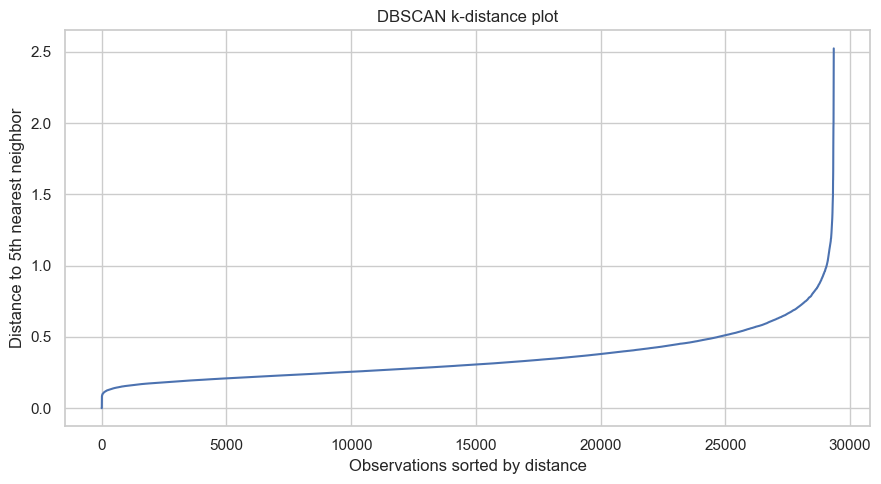

In [28]:
# ============================================================
# DBSCAN K-DISTANCE ANALYSIS
# ============================================================

neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_dev_scaled)
distances, _ = neighbors.kneighbors(X_dev_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel("Observations sorted by distance")
plt.ylabel("Distance to 5th nearest neighbor")
plt.title("DBSCAN k-distance plot")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "dbscan_k_distance.png"), dpi=300)
plt.show()

In [29]:
# ============================================================
# DBSCAN PARAMETER SEARCH
# ============================================================

def stratified_dbscan_silhouette(X, labels, max_samples=3000, random_state=42):
    labels = np.asarray(labels)
    keep = labels != -1
    X_non_noise = X[keep]
    y_non_noise = labels[keep]

    cluster_ids, counts = np.unique(y_non_noise, return_counts=True)
    valid_clusters = cluster_ids[counts >= 2]
    if len(valid_clusters) < 2:
        return np.nan, 0

    valid = np.isin(y_non_noise, valid_clusters)
    X_valid = X_non_noise[valid]
    y_valid = y_non_noise[valid]

    rng = np.random.default_rng(random_state)
    budget = min(max_samples, len(y_valid))
    chosen = []

    for cluster in valid_clusters:
        idx = np.flatnonzero(y_valid == cluster)
        chosen.extend(rng.choice(idx, size=2, replace=False).tolist())

    remaining_budget = max(0, budget - len(chosen))
    remaining = np.setdiff1d(np.arange(len(y_valid)), np.asarray(chosen, dtype=int))

    if remaining_budget > 0 and len(remaining) > 0:
        extra = rng.choice(
            remaining,
            size=min(remaining_budget, len(remaining)),
            replace=False
        )
        chosen.extend(extra.tolist())

    chosen = np.asarray(chosen, dtype=int)
    X_sample = X_valid[chosen]
    y_sample = y_valid[chosen]

    n_labels = len(np.unique(y_sample))
    if n_labels < 2 or n_labels >= len(y_sample):
        return np.nan, len(y_sample)

    return silhouette_score(X_sample, y_sample), len(y_sample)


eps_values = [0.5, 0.7, 0.9, 1.0, 1.2, 1.5, 2.0]
min_samples_values = [5, 10, 15, 20]
dbscan_rows = []

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_dev_scaled)

        non_noise = labels != -1
        cluster_labels = labels[non_noise]
        sizes = pd.Series(cluster_labels).value_counts()

        score, score_n = stratified_dbscan_silhouette(
            X_dev_scaled, labels,
            max_samples=3000,
            random_state=RANDOM_STATE
        )

        dbscan_rows.append({
            "eps": eps,
            "min_samples": min_samples,
            "Number of Clusters": len(set(labels) - {-1}),
            "Noise Count": int((labels == -1).sum()),
            "Noise Percentage": 100 * float((labels == -1).mean()),
            "Silhouette Score": score,
            "Silhouette Sample Size": score_n,
            "Minimum Cluster Size": int(sizes.min()) if len(sizes) else 0,
            "Maximum Cluster Size": int(sizes.max()) if len(sizes) else 0
        })

dbscan_search = pd.DataFrame(dbscan_rows)
display(dbscan_search.sort_values("Silhouette Score", ascending=False, na_position="last"))
dbscan_search.to_csv(os.path.join(OUTPUT_DIR, "dbscan_parameter_search.csv"), index=False)

,eps,min_samples,Number of Clusters,Noise Count,Noise Percentage,Silhouette Score,Silhouette Sample Size,Minimum Cluster Size,Maximum Cluster Size
18,1.2,15,2,99,0.337320,0.456282,3000,16,29234
16,1.2,5,2,45,0.153327,0.353454,3000,14,29290
17,1.2,10,2,67,0.228287,0.351112,3000,10,29272
12,1.0,5,3,129,0.439538,0.350263,3000,5,29206
15,1.0,20,2,441,1.502607,0.298356,3000,26,28882
11,0.9,20,2,812,2.766704,0.290336,3000,22,28515
10,0.9,15,2,675,2.299908,0.287102,3000,27,28647
9,0.9,10,4,480,1.635490,0.093819,3000,11,28814
6,0.7,15,5,2235,7.615251,0.010297,3000,11,27045
7,0.7,20,5,2754,9.383625,-0.070170,3000,22,26481


In [30]:
# ============================================================
# FINAL DBSCAN MODEL
# ============================================================

# Inspect the parameter-search table before choosing final values.
SELECTED_EPS = 1.0
SELECTED_MIN_SAMPLES = 10

dbscan_model = DBSCAN(eps=SELECTED_EPS, min_samples=SELECTED_MIN_SAMPLES)
dbscan_labels_dev = dbscan_model.fit_predict(X_dev_scaled)
development_data["DBSCAN_Cluster"] = dbscan_labels_dev

n_dbscan_clusters = len(set(dbscan_labels_dev) - {-1})
noise_percentage = 100 * np.mean(dbscan_labels_dev == -1)

print("Number of clusters:", n_dbscan_clusters)
print("Noise percentage:", round(noise_percentage, 2), "%")
display(development_data["DBSCAN_Cluster"].value_counts().sort_index().to_frame("count"))

dbscan_non_noise = development_data[development_data["DBSCAN_Cluster"] != -1].copy()

dbscan_feature_profiles = dbscan_non_noise.groupby("DBSCAN_Cluster")[feature_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
dbscan_target_profiles = dbscan_non_noise.groupby("DBSCAN_Cluster")[target_cols].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(dbscan_feature_profiles)
display(dbscan_target_profiles)

dbscan_feature_profiles.to_csv(os.path.join(OUTPUT_DIR, "dbscan_feature_profiles.csv"))
dbscan_target_profiles.to_csv(os.path.join(OUTPUT_DIR, "dbscan_cluster_profiles.csv"))

Number of clusters: 1
Noise percentage: 0.83 %


,count
DBSCAN_Cluster,
-1,244
0,29105


AT                                                   AP  \
                count       mean  median       std      min     max  count   
DBSCAN_Cluster                                                               
0               29105  17.887482  17.974  7.257531  0.28985  34.929  29105   

                                               ...    TAT                    \
                       mean  median       std  ... median       std     min   
DBSCAN_Cluster                                 ...                            
0               1012.707892  1012.3  6.236802  ...  549.9  7.071774  513.06   

                          CDP                                              
                   max  count      mean  median       std     min     max  
DBSCAN_Cluster                                                             
0               550.61  29105  12.05201  11.968  1.074834  9.8518  15.081  

[1 rows x 48 columns]

TEY                                                    CO  \
                count        mean  median        std     min     max  count   
DBSCAN_Cluster                                                                
0               29105  133.399653  133.75  15.429091  100.14  174.61  29105   

                                                                NOX  \
                    mean  median       std       min     max  count   
DBSCAN_Cluster                                                        
0               2.135836  1.5588  1.983864  0.000388  43.428  29105   

                                                              
                     mean  median        std     min     max  
DBSCAN_Cluster                                                
0               66.514329  64.861  11.274157  27.183  119.91

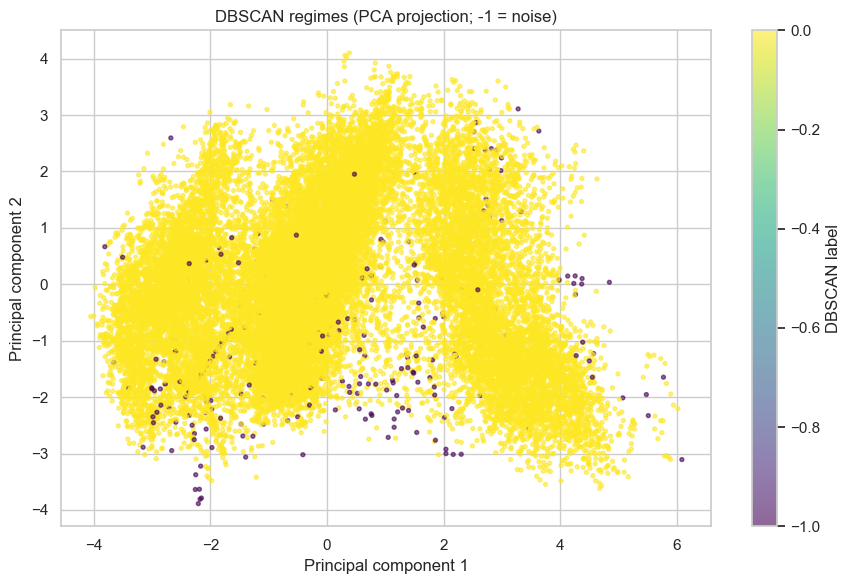

In [31]:
# ============================================================
# PCA DBSCAN VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 6))
sc = plt.scatter(
    X_dev_pca[:, 0], X_dev_pca[:, 1],
    c=dbscan_labels_dev, cmap="viridis", s=8, alpha=0.6
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("DBSCAN regimes (PCA projection; -1 = noise)")
plt.colorbar(sc, label="DBSCAN label")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "PCA_DBSCAN_clusters.png"), dpi=300)
plt.show()

In [32]:
# ============================================================
# CLUSTERING METHOD COMPARISON
# ============================================================

kmeans_sil = silhouette_score(
    X_dev_scaled, kmeans_labels_dev,
    sample_size=min(5000, len(X_dev_scaled)),
    random_state=RANDOM_STATE
)
dbscan_sil, dbscan_sil_n = stratified_dbscan_silhouette(
    X_dev_scaled, dbscan_labels_dev,
    max_samples=3000,
    random_state=RANDOM_STATE
)

clustering_comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Number of Clusters": [SELECTED_K, n_dbscan_clusters],
    "Silhouette Score": [kmeans_sil, dbscan_sil],
    "Silhouette Sample Size": [min(5000, len(X_dev_scaled)), dbscan_sil_n],
    "Noise Percentage": [0.0, noise_percentage]
})
display(clustering_comparison)
clustering_comparison.to_csv(os.path.join(OUTPUT_DIR, "clustering_comparison.csv"), index=False)

print("DBSCAN silhouette excludes noise; K-Means silhouette includes all observations.")

,Algorithm,Number of Clusters,Silhouette Score,Silhouette Sample Size,Noise Percentage
0,K-Means,4,0.29101,5000,0.000000
1,DBSCAN,1,NaN,0,0.831374


DBSCAN silhouette excludes noise; K-Means silhouette includes all observations.


KMeans_Cluster,0,1,2,3
YEAR,,,,
2011,34.367832,23.613547,21.589529,20.429092
2012,30.165181,14.997378,32.288936,22.548506
2013,32.368568,18.694072,22.427293,26.510067
2014,39.969265,12.796871,26.599609,20.634255
2015,29.225352,12.676056,34.588299,23.510293


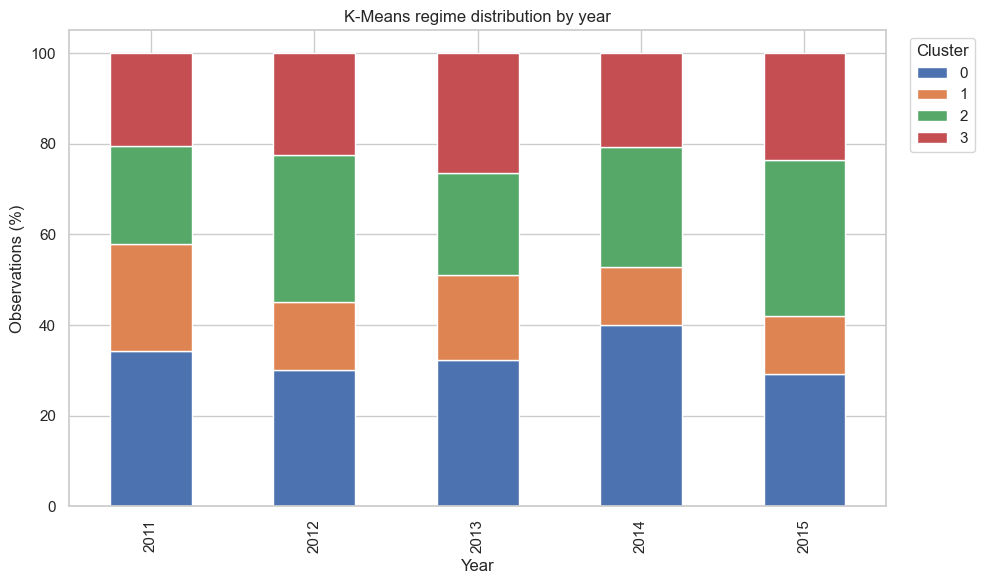

In [33]:
# ============================================================
# YEAR-WISE REGIME COMPARISON
# ============================================================

year_distribution = pd.crosstab(
    development_data["YEAR"],
    development_data["KMeans_Cluster"],
    normalize="index"
) * 100

dist_2015 = (
    comparison_data["KMeans_Cluster"]
    .value_counts(normalize=True)
    .reindex(range(SELECTED_K), fill_value=0)
    .sort_index() * 100
)
year_distribution.loc[2015] = dist_2015.values
year_distribution = year_distribution.sort_index()

display(year_distribution)
year_distribution.to_csv(os.path.join(OUTPUT_DIR, "year_wise_cluster_distribution.csv"))

ax = year_distribution.plot(kind="bar", stacked=True, figsize=(10, 6))
ax.set_xlabel("Year")
ax.set_ylabel("Observations (%)")
ax.set_title("K-Means regime distribution by year")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "year_wise_cluster_distribution.png"), dpi=300)
plt.show()

In [34]:
# ============================================================
# EXPORT RESULTS
# ============================================================

development_data.to_csv(
    os.path.join(OUTPUT_DIR, "development_cluster_assignments.csv"),
    index=False
)
comparison_data.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_2015_cluster_assignments.csv"),
    index=False
)

settings = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Configuration": f"K={SELECTED_K}, n_init=10, random_state={RANDOM_STATE}",
        "Fit data": "2011–2014"
    },
    {
        "Algorithm": "DBSCAN",
        "Configuration": f"eps={SELECTED_EPS}, min_samples={SELECTED_MIN_SAMPLES}",
        "Fit data": "2011–2014"
    }
])
settings.to_csv(os.path.join(OUTPUT_DIR, "clustering_model_settings.csv"), index=False)

print("Notebook completed. Results saved in:", os.path.abspath(OUTPUT_DIR))

Notebook completed. Results saved in: c:\Users\devra\Music\gas-turbine-ml\outputs\unsupervised
